<a href="https://colab.research.google.com/github/GAEL328530/Lab-pdi-PR-CTICAS/blob/main/Practica7_SegmentacionOptima.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Práctica 7. Segmentación óptima**

**Universidad Autónoma de Nuevo León – Facultad de Ingeniería Mecánica y Eléctrica**
Procesamiento Digital de Imágenes

**Qué se hace en este notebook:** se segmenta una imagen médica (tomografía de cráneo con un tumor) con dos métodos: una segmentación sencilla y una segmentación óptima, donde el método de optimización SLSQP calcula los coeficientes de los canales R, G y B. Después se elimina el ruido, se dibujan los contornos del cráneo y del tumor y se calcula el área del tumor.

| Integrante | Matrícula | Brigada | Día y hora |
|---|---|---|---|
|Alexa Rodríguez Méndez |2133921 |309 |n5 |
|Gael Alejandro Reyes Zaragoza |2178099 |309 |n5 |
|René Alejandro Rodríguez Castañeda |2019068 |309 |n5 |

## **1. Librerías**

Se importan OpenCV (lectura y procesamiento de la imagen), NumPy (operaciones con matrices), Matplotlib (gráficas) y `minimize` de SciPy (algoritmo de optimización).

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

## **2. Carga de la imagen**

Se descarga la imagen `Te-me_0015.jpg` del repositorio de la clase (si ya está en la carpeta de Colab, no se vuelve a descargar). OpenCV la lee en formato BGR, por lo que se convierte a RGB y se separan los tres canales.

Tamaño de la imagen (alto, ancho, canales): (605, 507, 3)
¿R, G y B son idénticos?: True


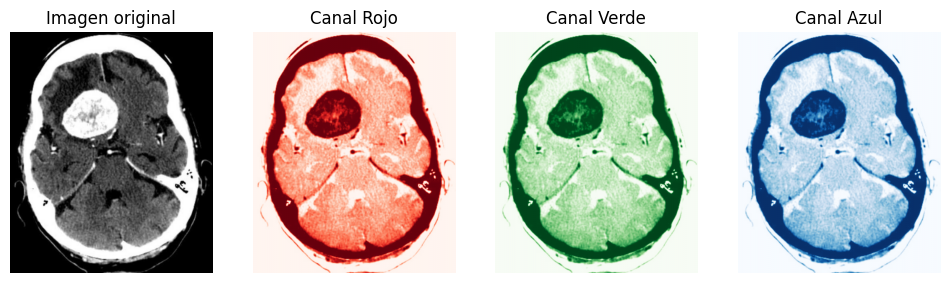

In [ ]:
url = 'https://raw.githubusercontent.com/dilp90/PDI/main/Imagenes/Te-me_0015.jpg'
ruta = 'Te-me_0015.jpg'

if not os.path.exists(ruta):
    !wget -q -O {ruta} {url}

img = cv2.imread(ruta)
if img is None:
    raise FileNotFoundError('No se pudo leer la imagen. Súbela manualmente a /content/')

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
R, G, B = img_rgb[:, :, 0], img_rgb[:, :, 1], img_rgb[:, :, 2]

print('Tamaño de la imagen (alto, ancho, canales):', img_rgb.shape)
print('¿R, G y B son idénticos?:', np.array_equal(R, G) and np.array_equal(G, B))

plt.figure(figsize=(12, 4))
for i, (c, nombre, cmap) in enumerate([(img_rgb, 'Imagen original', None), (R, 'Canal Rojo', 'Reds'),
                                       (G, 'Canal Verde', 'Greens'), (B, 'Canal Azul', 'Blues')]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(c, cmap=cmap)
    plt.title(nombre)
    plt.axis('off')
plt.show()

## **3. Segmentación sencilla**

1. Se convierte a escala de grises **promediando** los tres canales.
2. Se aplica un umbral fijo de 100 (el mismo del notebook de referencia) para obtener una imagen binaria.

También se muestra el histograma, que sirve para elegir después un umbral más adecuado.

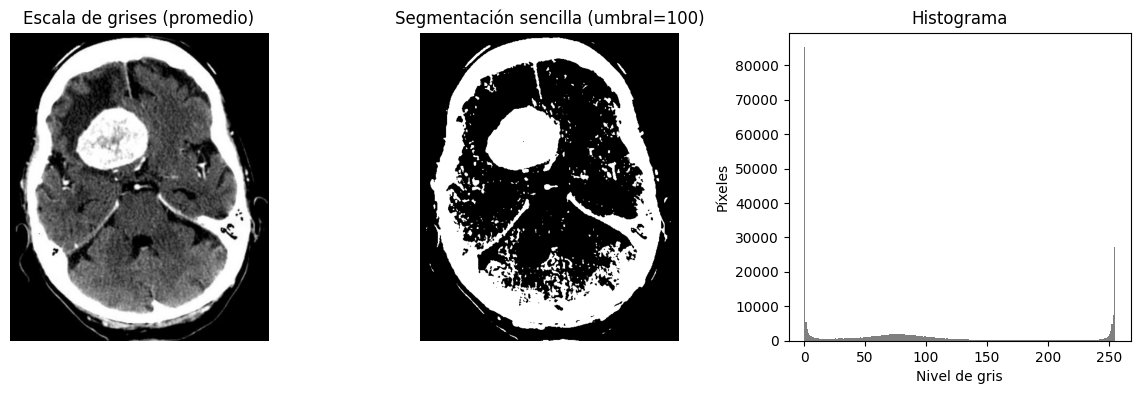

In [ ]:
gray_avg = ((R.astype(np.float32) + G + B) / 3).astype(np.uint8)

umbral = 100
_, segmentada = cv2.threshold(gray_avg, umbral, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(gray_avg, cmap='gray')
plt.title('Escala de grises (promedio)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(segmentada, cmap='gray')
plt.title(f'Segmentación sencilla (umbral={umbral})')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.hist(gray_avg.ravel(), bins=256, range=(0, 255), color='gray')
plt.title('Histograma')
plt.xlabel('Nivel de gris')
plt.ylabel('Píxeles')
plt.show()

## **4. Segmentación óptima con SLSQP**

Se buscan los pesos $[w_r, w_g, w_b]$ de

$$Gris(i,j) = w_r \cdot R(i,j) + w_g \cdot G(i,j) + w_b \cdot B(i,j)$$

con la restricción $w_r + w_g + w_b = 1$ y cada peso entre 0 y 1. El criterio es **maximizar la varianza** de la imagen en gris normalizada (mayor varianza = mayor contraste). Como `minimize()` minimiza, la función objetivo regresa la varianza con signo negativo.

In [ ]:
# Canales normalizados entre 0 y 1
R_norm = R.astype(np.float32) / 255
G_norm = G.astype(np.float32) / 255
B_norm = B.astype(np.float32) / 255

def grayscale_variance(weights):
    w_r, w_g, w_b = weights
    gray = w_r * R_norm + w_g * G_norm + w_b * B_norm
    gray_normalized = (gray - gray.min()) / (gray.max() - gray.min())
    return -np.var(gray_normalized)   # negativo para maximizar

constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})
bounds = [(0, 1), (0, 1), (0, 1)]
initial_weights = [0.33, 0.33, 0.34]

result = minimize(grayscale_variance, initial_weights, method='SLSQP',
                  bounds=bounds, constraints=constraints)

optimal_weights = result.x
print('Pesos óptimos [w_r, w_g, w_b]:', np.round(optimal_weights, 4))
print('Suma de pesos:', round(float(np.sum(optimal_weights)), 4))
print('Varianza máxima:', round(float(-result.fun), 6))
print('¿Convergió?:', result.success, '-', result.message)

Pesos óptimos [w_r, w_g, w_b]: [0.33 0.33 0.34]
Suma de pesos: 1.0
Varianza máxima: 0.12694
¿Convergió?: True - Optimization terminated successfully


**Nota sobre el resultado:** la imagen es una tomografía en escala de grises guardada como RGB, es decir, R = G = B en todos los píxeles. Entonces $Gris = (w_r + w_g + w_b)\cdot I = I$ para cualquier combinación que sume 1, y la varianza no cambia con los pesos. Por eso SLSQP termina de inmediato en el punto inicial. El método sí se ejecuta tal cual se pide; solo que, con este tipo de imagen, todas las combinaciones son igual de óptimas.

Diferencia máxima entre gris promedio y gris óptimo: 0 nivel(es)


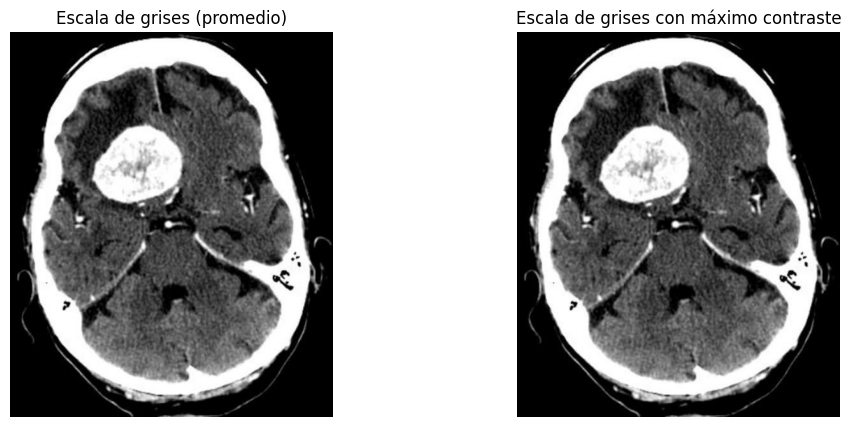

In [ ]:
gray_optimal = optimal_weights[0] * R_norm + optimal_weights[1] * G_norm + optimal_weights[2] * B_norm
gray_optimal = (gray_optimal * 255).astype(np.uint8)

print('Diferencia máxima entre gris promedio y gris óptimo:', int(np.abs(gray_avg.astype(int) - gray_optimal.astype(int)).max()), 'nivel(es)')

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray_avg, cmap='gray')
plt.title('Escala de grises (promedio)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(gray_optimal, cmap='gray')
plt.title('Escala de grises con máximo contraste')
plt.axis('off')
plt.show()

## **5. Umbral para aislar tumor y cráneo**

Con el umbral 100 se incluye mucho tejido cerebral, así que no sirve para separar las estructuras. Tanto el cráneo como el tumor (con medio de contraste) son las zonas más brillantes de la imagen, por lo que se prueba un umbral alto. Aquí se compara el umbral 100 contra el umbral 190 sobre la imagen óptima.

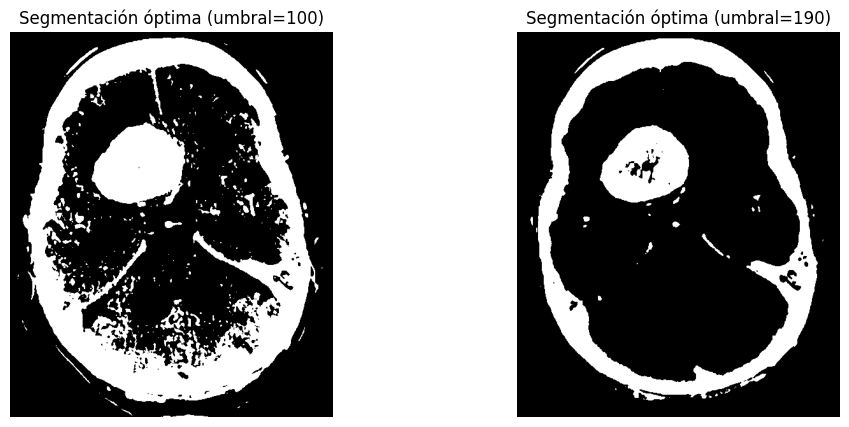

In [ ]:
_, seg_100 = cv2.threshold(gray_optimal, 100, 255, cv2.THRESH_BINARY)
umbral_alto = 190
_, seg_alto = cv2.threshold(gray_optimal, umbral_alto, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(seg_100, cmap='gray')
plt.title('Segmentación óptima (umbral=100)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(seg_alto, cmap='gray')
plt.title(f'Segmentación óptima (umbral={umbral_alto})')
plt.axis('off')
plt.show()

## **6. Eliminación de ruido**

Con el umbral alto aún quedan puntos aislados y bordes irregulares. Se limpia con:

1. **Apertura morfológica** (erosión + dilatación) con un elemento elíptico de 3×3, que borra los puntos pequeños.
2. **Componentes conexas**: se conserva el componente más grande (el cráneo) y el componente brillante más grande que no está conectado a él (el tumor); el resto se descarta por ser ruido.

Componentes encontrados (sin fondo): 27
Área del cráneo (píxeles): 47142
Área del tumor antes de rellenar (píxeles): 11536


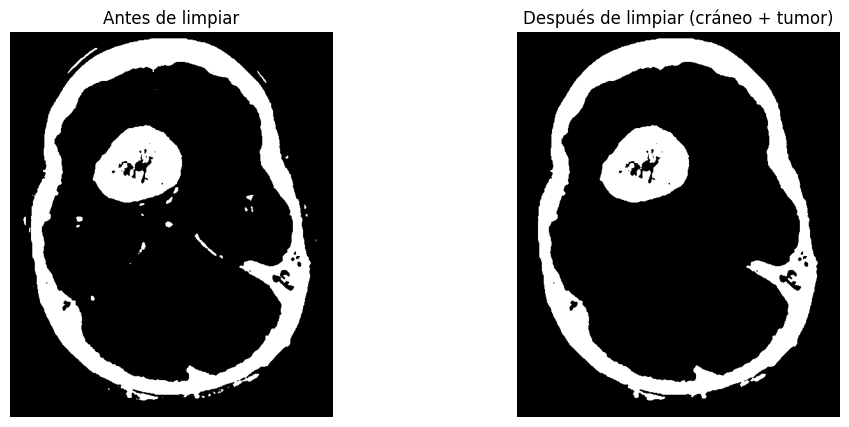

In [ ]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
limpia = cv2.morphologyEx(seg_alto, cv2.MORPH_OPEN, kernel)

n, etiquetas, stats, centroides = cv2.connectedComponentsWithStats(limpia, connectivity=8)
areas = stats[1:, cv2.CC_STAT_AREA]
id_craneo = 1 + int(np.argmax(areas))

candidatos = [i for i in range(1, n) if i != id_craneo and stats[i, cv2.CC_STAT_AREA] > 1000]
id_tumor = max(candidatos, key=lambda i: stats[i, cv2.CC_STAT_AREA])

craneo = (etiquetas == id_craneo).astype(np.uint8) * 255
tumor = (etiquetas == id_tumor).astype(np.uint8) * 255

print('Componentes encontrados (sin fondo):', n - 1)
print('Área del cráneo (píxeles):', int(stats[id_craneo, cv2.CC_STAT_AREA]))
print('Área del tumor antes de rellenar (píxeles):', int(stats[id_tumor, cv2.CC_STAT_AREA]))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(seg_alto, cmap='gray')
plt.title('Antes de limpiar')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(craneo | tumor, cmap='gray')
plt.title('Después de limpiar (cráneo + tumor)')
plt.axis('off')
plt.show()

## **7. Contornos del cráneo y del tumor**

El interior del tumor tiene pequeños huecos oscuros, así que primero se aplica un cierre morfológico para unirlos. Luego `cv2.findContours` obtiene los contornos: los del cráneo (se descartan los menores a 1000 px² por ser ruido) y el contorno externo del tumor. Se dibujan solos y encima de la imagen original.

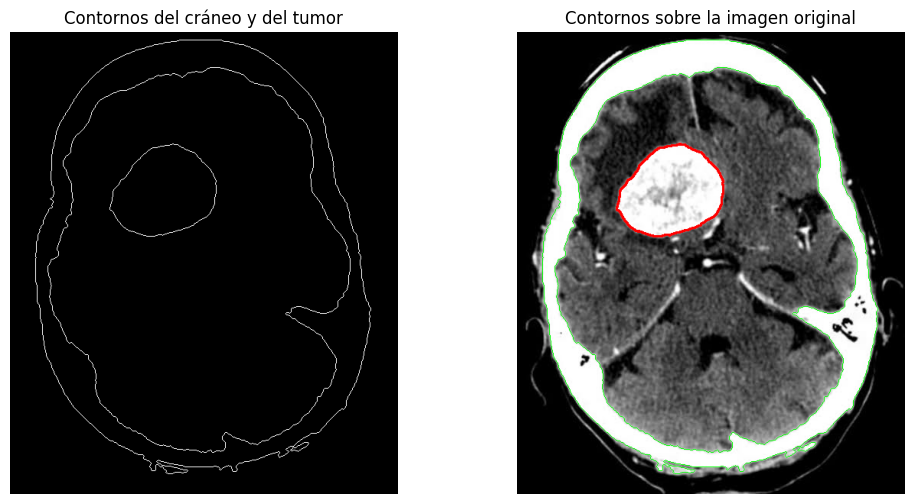

In [ ]:
tumor_cerrado = cv2.morphologyEx(tumor, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))

cont_craneo, _ = cv2.findContours(craneo, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
cont_craneo = [c for c in cont_craneo if cv2.contourArea(c) > 1000]

cont_tumor, _ = cv2.findContours(tumor_cerrado, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cont_tumor = max(cont_tumor, key=cv2.contourArea)

solo_contornos = np.zeros_like(gray_optimal)
cv2.drawContours(solo_contornos, cont_craneo, -1, 255, 1)
cv2.drawContours(solo_contornos, [cont_tumor], -1, 255, 1)

superpuesta = img_rgb.copy()
cv2.drawContours(superpuesta, cont_craneo, -1, (0, 255, 0), 1)
cv2.drawContours(superpuesta, [cont_tumor], -1, (255, 0, 0), 2)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(solo_contornos, cmap='gray')
plt.title('Contornos del cráneo y del tumor')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(superpuesta)
plt.title('Contornos sobre la imagen original')
plt.axis('off')
plt.show()

## **8. Área del tumor**

Se rellena el contorno del tumor y se cuentan los píxeles que contiene. Además se calcula el perímetro, el diámetro equivalente y el porcentaje del área del tumor respecto a la imagen. La imagen no trae escala, así que el área está en píxeles; si se conoce el tamaño del píxel, se puede escribir en `mm_por_pixel` para obtener mm².

Área del tumor: 12339 píxeles²
Perímetro del tumor: 429.3 píxeles
Diámetro equivalente: 125.3 píxeles
Porcentaje de la imagen: 4.02 %


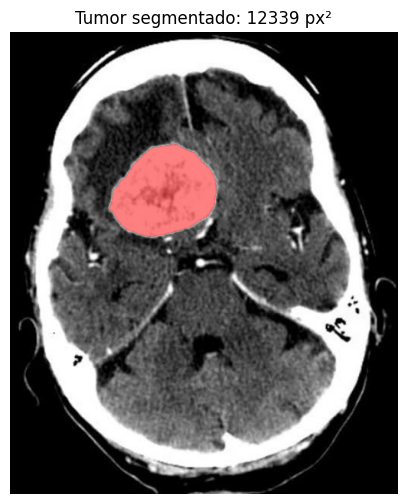

In [ ]:
mascara_tumor = np.zeros_like(gray_optimal)
cv2.drawContours(mascara_tumor, [cont_tumor], -1, 255, -1)

area_px = int(np.count_nonzero(mascara_tumor))
perimetro_px = cv2.arcLength(cont_tumor, True)
diametro_eq = np.sqrt(4 * area_px / np.pi)
porcentaje = 100 * area_px / mascara_tumor.size

print(f'Área del tumor: {area_px} píxeles²')
print(f'Perímetro del tumor: {perimetro_px:.1f} píxeles')
print(f'Diámetro equivalente: {diametro_eq:.1f} píxeles')
print(f'Porcentaje de la imagen: {porcentaje:.2f} %')

mm_por_pixel = None   # ejemplo: 0.5 si cada píxel mide 0.5 mm
if mm_por_pixel is not None:
    print(f'Área del tumor: {area_px * mm_por_pixel**2:.1f} mm²')

plt.figure(figsize=(5, 6))
plt.imshow(img_rgb)
plt.imshow(np.ma.masked_where(mascara_tumor == 0, mascara_tumor), cmap='autumn', alpha=0.5)
plt.title(f'Tumor segmentado: {area_px} px²')
plt.axis('off')
plt.show()